# Mosaic integration: [RNA, RNA + ATAC, ATAC]

Mosaic integration combines batches that share only some modalities, and every mosaic method reads ATAC as peaks. This tutorial is for an RNA batch, an RNA + ATAC batch and an ATAC batch. It runs StabMap and scMoMaT on `D45mini`, 6,000 cells of the benchmark dataset `D45`, and then on data in your own format.

StabMap and scMoMaT run on Linux, Windows and macOS (Apple silicon). Or [open in Colab](https://colab.research.google.com/github/DSichang/scMultiBench/blob/main/notebooks/tutorial_mosaic_rna_atac.ipynb): sections 1 to 4 take about 12 minutes there.

## 1. Install

pip may then print a note about restarting the kernel: no restart is needed, because the pins keep the numpy and pandas already installed.

In [1]:
import numpy, pandas
pins = f"numpy=={numpy.__version__} pandas=={pandas.__version__}"
%pip install -q "multibench-sc>=0.7.4" {pins}

Note: you may need to restart the kernel to use updated packages.


## 2. Download the data and the environments

`mtb.data.fetch` downloads `D45mini` (11 MB) once. `mtb.env.install` downloads the environments for StabMap and scMoMaT. On Linux the download is 1.8 GB on a computer without a GPU and 5.4 GB on one with a GPU. On Windows it is 0.6 GB and 2.5 GB. On macOS it is 1.0 GB.

In [2]:
import multibench as mtb
import pandas as pd

pd.set_option("display.max_columns", None)   # show every column of the tables

mtb.data.fetch("D45mini")
METHODS = ["StabMap", "scMoMaT"]
envs = mtb.env.install(METHODS)

downloading D45mini (11 MB) ...


## 3. Run the methods

`run` runs each method on `D45mini` and [scores its output](https://dsichang.github.io/scMultiBench/tutorials/evaluate/#what-each-metric-measures). The clustering metrics score how well the embedding's clusters and neighbourhoods match the cell types, and how separate the clusters are. The batch metrics measure how well the batches mix. The classification scores measure how well the cell types learned on one batch are predicted in the other batches. scMoMaT writes a graph: `run` scores that graph, which has no ASW, iASW or ASW_batch and no classification scores. Higher is better for every metric.

<details>
<summary>Details</summary>

`params={"Method": {"key": value}}` sets a method's parameters, and `mtb.params_for` lists them.

`mtb.load_run("out/D45mini")` reloads these results later.

</details>

In [3]:
res = mtb.run("D45mini", "mosaic", methods=METHODS, out_dir="out/D45mini")
res.summary

[run] StabMap (mosaic/D45mini) ...
[run]   -> scored (14.9s) ARI 0.526
[run] scMoMaT (mosaic/D45mini) ...
[run]   -> scored (80.9s) ARI 0.343


,method,status,ARI,NMI,ASW,iASW,iF1,cLISI,ASW_batch,ARI_batch,NMI_batch,GC,iLISI,OCA,ACA,Spec,Sens,F1,run_sec,caveat,reason
0,StabMap,scored,0.5256,0.6537,0.5441,0.5733,0.6335,0.9510,0.8541,0.9996,0.9993,0.9783,0.432,0.8602,0.7882,0.9875,0.7882,0.8103,14.9,,
1,scMoMaT,scored,0.3433,0.5328,NaN,NaN,0.5203,0.8488,NaN,0.9990,0.9989,0.9868,0.960,NaN,NaN,NaN,NaN,NaN,80.9,,


## 4. Plot

`res.plot()` draws the scores as a bubble table. Circle size ranks the rows within each column and colour shows the value scaled per column, so a small gap can look large. `res.summary` has the values.

<details>
<summary>Details</summary>

Metrics are grouped by family: blue for clustering, green for batch correction, pink for classification. Each family starts with an `Overall` bar: each row's mean rank over the family's metrics, scaled so that the lowest gets the shortest bar.

A column with fewer than two different values is drawn grey. A figure of one method is grey everywhere.

</details>

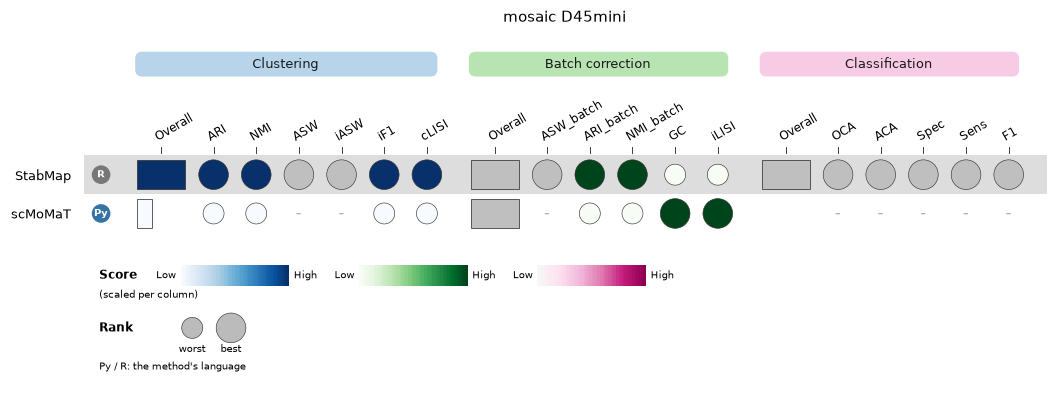

In [4]:
res.plot()

## 5. Your own data

Your data needs raw counts, with one `.h5ad` file per batch and modality and a cell type for each cell. Number the batches as below: RNA, then RNA + ATAC, then ATAC. Give ATAC as peaks.

Every RNA file needs the same gene names and every ATAC file the same peaks, in the same order. scMoMaT matches the features of two batches by position, and the check does not compare their names across batches.

Recipes cover [a 10x `.h5` file](https://dsichang.github.io/scMultiBench/tutorials/run/#recipe-10x-h5), [labels in a CSV file](https://dsichang.github.io/scMultiBench/tutorials/run/#recipe-labels-csv) and [no labels](https://dsichang.github.io/scMultiBench/tutorials/run/#recipe-no-labels).

<details>
<summary>Details: export</summary>

[The folder layout](https://dsichang.github.io/scMultiBench/tutorials/run/#folder-layout) lists the batch patterns and the methods that accept each one.

</details>

The next cell writes four small example files, one per batch and modality, from the first 1,500 cells of each batch of `D45mini`. Skip it for your own data.

In [5]:
mtb.data.write_example("D45mini")

wrote my_rna1.h5ad: 1,500 cells. RNA counts in X, cell types in obs["celltype"].
wrote my_rna2.h5ad: 1,500 cells. RNA counts in X, cell types in obs["celltype"].
wrote my_atac2.h5ad: 1,500 cells. ATAC peak counts in X, cell types in obs["celltype"].
wrote my_atac3.h5ad: 1,500 cells. ATAC peak counts in X, cell types in obs["celltype"].


Read your files. For your own data, change every file name marked `# <-`. On Colab, upload the files first: click the folder icon on the left, then the upload icon.

In [6]:
import anndata as ad

rna1 = ad.read_h5ad("my_rna1.h5ad")     # <- batch 1: your RNA file
rna2 = ad.read_h5ad("my_rna2.h5ad")     # <- batch 2: your RNA file
atac2 = ad.read_h5ad("my_atac2.h5ad")   # <- batch 2: peaks of the same cells
atac3 = ad.read_h5ad("my_atac3.h5ad")   # <- batch 3: your peak file
print(rna2)
print(atac2)

AnnData object with n_obs × n_vars = 1500 × 1000
    obs: 'celltype'
    layers: None (.X)
AnnData object with n_obs × n_vars = 1500 × 5000
    obs: 'celltype'
    layers: None (.X)


Write the dataset folder. Change each name in quotes marked `# <-` to one the printout above lists for two of your files, with its prefix, as `"obs:celltype"`.

In [7]:
NAME = "MYMOSAIC_RNA_ATAC"   # <- a new name for your own data
folder = "mydata/" + NAME
celltype = "obs:celltype"   # <- the cell-type column of every file
# batch 1: RNA only
mtb.io.export_dataset(rna1, folder, rna="X", labels=celltype,
                      batch_index=1, category="mosaic", overwrite=True)
# batch 2: RNA + ATAC peaks
mtb.io.export_dataset(rna2, folder, rna="X", atac=atac2, atac_kind="peak",
                      labels=celltype,
                      batch_index=2, category="mosaic", overwrite=True)
# batch 3: ATAC peaks only
mtb.io.export_dataset(atac3, folder, rna=None, atac="X", atac_kind="peak",
                      labels=celltype,
                      batch_index=3, category="mosaic", overwrite=True)
mtb.scan("mydata/" + NAME, "mosaic", methods=METHODS)

[scan] 2 of 2 methods have their input files in MYMOSAIC_RNA_ATAC. 2 of 2 can run on this computer. MYMOSAIC_RNA_ATAC holds RNA and ATAC, in batches 1-3.
[scan] Cells per file: rna1.h5 1,500, rna2.h5 1,500, atac2.h5 1,500, atac3.h5 1,500.


,method,modalities,runnable,reason,env,caveat
0,StabMap,rna1+rna2+atac2+atac3,True,,scmb_r,
1,scMoMaT,rna1+rna2+atac2+atac3,True,,scmb_torch,


In [8]:
mine = mtb.run("mydata/" + NAME, "mosaic", methods=METHODS,
               out_dir="out/" + NAME)
mine.summary

[run] StabMap (mosaic/MYMOSAIC_RNA_ATAC) ...
[run]   -> scored (13.7s) ARI 0.463
[run] scMoMaT (mosaic/MYMOSAIC_RNA_ATAC) ...
[run]   -> scored (77.8s) ARI 0.393


,method,status,ARI,NMI,ASW,iASW,iF1,cLISI,ASW_batch,ARI_batch,NMI_batch,GC,iLISI,OCA,ACA,Spec,Sens,F1,run_sec,caveat,reason
0,StabMap,scored,0.4629,0.6197,0.5411,0.594,0.5934,0.9363,0.8463,0.9997,0.9966,0.9488,0.4317,0.8502,0.7645,0.9867,0.7645,0.7851,13.7,,
1,scMoMaT,scored,0.3934,0.5604,NaN,NaN,0.5473,0.9033,NaN,0.9996,0.9994,0.9768,0.9727,NaN,NaN,NaN,NaN,NaN,77.8,,


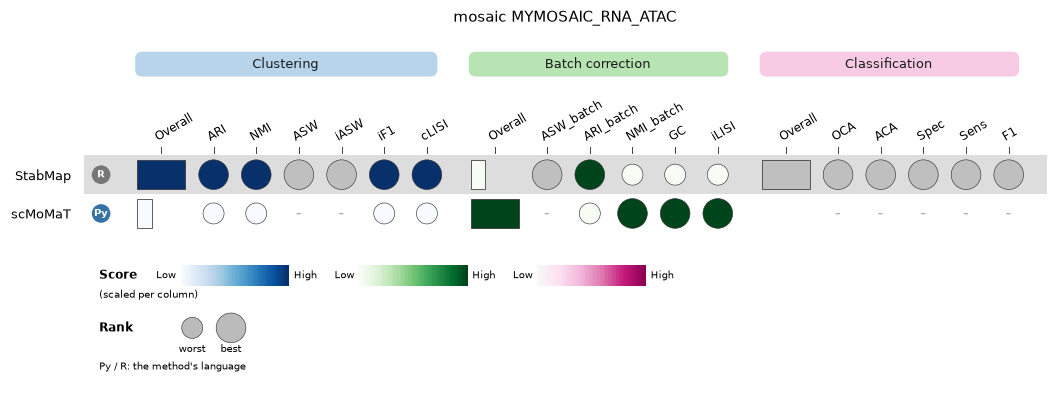

In [9]:
mine.plot()

## 6. Stored results

The package ships stored results for 4 methods on the full `D45`. `load_results` reads them and `mtb.plot.bubble` draws them, without running anything.

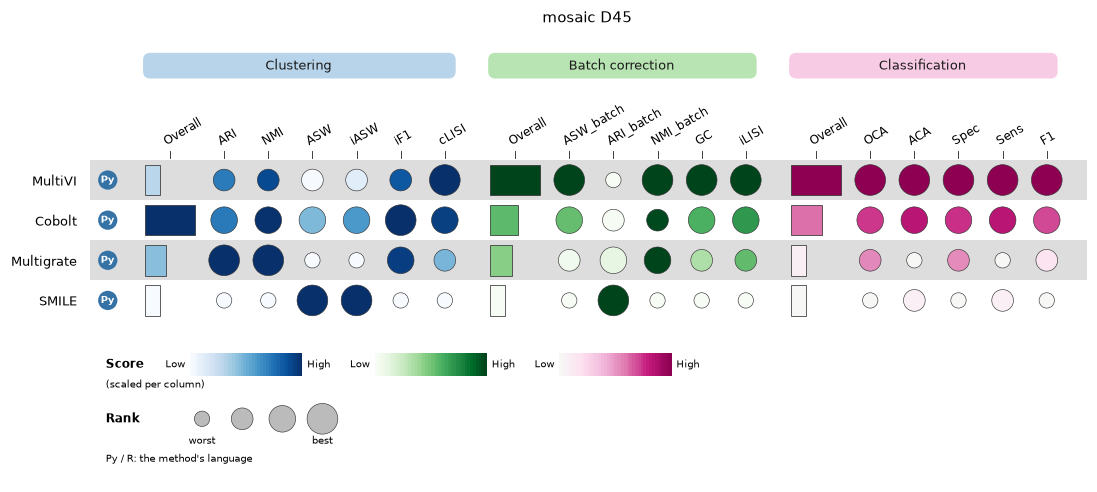

In [10]:
stored = mtb.load_results("mosaic", dataset="D45")
mtb.plot.bubble(stored)

## 7. Every method of this task

6 methods run this task. [This notebook](https://colab.research.google.com/github/DSichang/scMultiBench/blob/main/notebooks/tutorial_mosaic_rna_atac_all.ipynb) runs them all. Its 6 environments download 7.8 GB on a computer without a GPU and 8.9 GB on one with a GPU.

## Troubleshooting

`res.summary[res.summary.status != "scored"]` lists each method that failed or was skipped. Its `reason` column ends with the method's error output.

<details>
<summary>Details</summary>

| symptom | fix |
|---|---|
| a method fails on a small dataset | `mtb.scan` names what the method needs from the data's size in its `caveat` column |
| batch metrics use the wrong batches | `res.rescore(batch=...)`, with one batch per cell, scores again without running the methods |

</details>

## Next steps

- [Run a method](https://dsichang.github.io/scMultiBench/tutorials/run/), [Score an embedding](https://dsichang.github.io/scMultiBench/tutorials/evaluate/), [Load and plot results](https://dsichang.github.io/scMultiBench/tutorials/plot/) and [Discover methods](https://dsichang.github.io/scMultiBench/tutorials/discover/).
- [Look at an embedding](https://dsichang.github.io/scMultiBench/tutorials/evaluate/#look-at-an-embedding) draws a method's embedding as a UMAP.
- The [interactive explorer](https://shiny.maths.usyd.edu.au/scMultiBench/) has the full benchmark's rankings, with no install needed.